# QePT
Here we introduce you to Quantum-enhanced Parallel Tempering (PT)

The basic idea of the approach is to use the [QeMCMC](https://www.nature.com/articles/s41586-023-06095-4) subroutine within Parallel Tempering. The details can be found in our paper: [Methods for non-variational heuristic quantum optimisation
](https://arxiv.org/abs/2602.01353)


## Imports

In [1]:
from joblib import Parallel, delayed
from matplotlib import pyplot as plt

# This helps you build an example Ising model
from qemcmc.model import ModelMaker

# Internal imports from QeMCMC package
# sampler contains the classical and quantum enhanced MCMC sampler
from qemcmc.sampler import ClassicalProposal, AdiabaticProposal, QuenchProposal
from qemcmc.sampler.runners import MCMCRunner
from qemcmc.coarse_grain import CoarseGraining
# These are object useful to store the results of the MCMC simulation
from qemcmc.utils import plot_chains

import numpy as np
from tqdm import tqdm
from qept.qept import QePT
import time


## Define model problem and algorithm parameters

In [68]:

# Define parameters
n = 12 # Number of spins in the system
reps = c_reps = 5 # How many markov chains to produce

n_steps = steps = n_hops = 100 # Length of each markov chain

m_replica = 4

high_temp = 10.0
low_temp = 0.01
temps = np.logspace(np.log10(high_temp), np.log10(low_temp), m_replica)
model = ModelMaker(n, "Fully Connected Ising", "test").model

model_lowest = model.lowest_energy



In [69]:
def run_single_repetition(model, proposals, n_hops, temps):
    """Worker function to handle a single simulation run."""
    pt = QePT(model, proposals=proposals)
    current_states, energy_history = pt.run(n_steps=n_hops, temps=temps, n_steps_between_exchange=2, verbose = True)
    
    return energy_history

In [70]:
g = (0.3,0.5)
t = (1,10)
m = 1
cg = CoarseGraining(model.n, m = m, repeated = False)
qeproposal = QuenchProposal(model, g, t, coarse_graining = cg)
cproposal = ClassicalProposal(model, method = "local")

q_chains = []
for _ in tqdm(range(reps)):
    q_chains.append(run_single_repetition(model, [qeproposal,]+([cproposal]*(m_replica-1)), n_hops, temps))




100%|██████████| 5/5 [00:25<00:00,  5.18s/it]


In [71]:
gamma = 3.0
alpha = 1.5
kappa = (0,3)
cg = CoarseGraining(model.n, m = m, repeated = False)
adiproposal = AdiabaticProposal(model, gamma, alpha, kappa, delta_t = 0.3, coarse_graining=cg)
adi_chains = []
for _ in tqdm(range(reps)):
    adi_chains.append(run_single_repetition(model, [adiproposal,]+([cproposal]*(m_replica-1)), n_hops, temps))



100%|██████████| 5/5 [01:42<00:00, 20.57s/it]


In [72]:
cproposal = ClassicalProposal(model, method = "local")
c_chains = []
for _ in tqdm(range(reps)):
    c_chains.append(run_single_repetition(model, [cproposal]*(m_replica), n_hops, temps))

uniproposal = ClassicalProposal(model, method = "uniform")
uni_chains = []
for _ in tqdm(range(reps)):
    uni_chains.append(run_single_repetition(model, [uniproposal]*(m_replica), n_hops, temps))



100%|██████████| 5/5 [00:00<00:00, 35.76it/s]


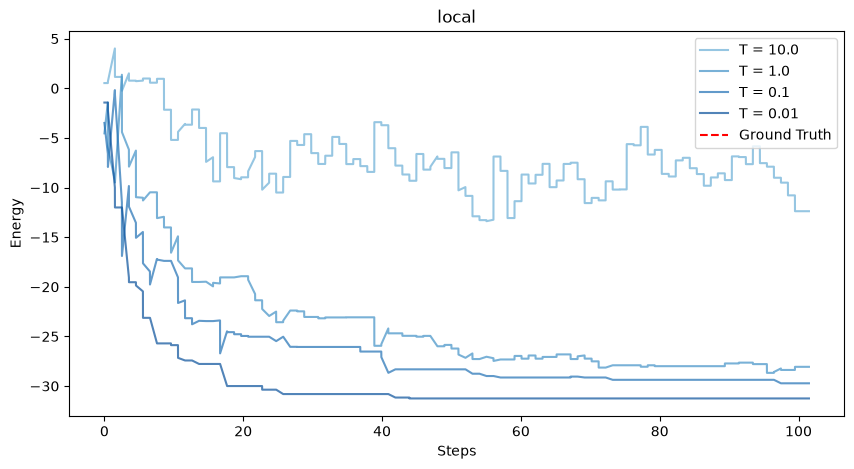

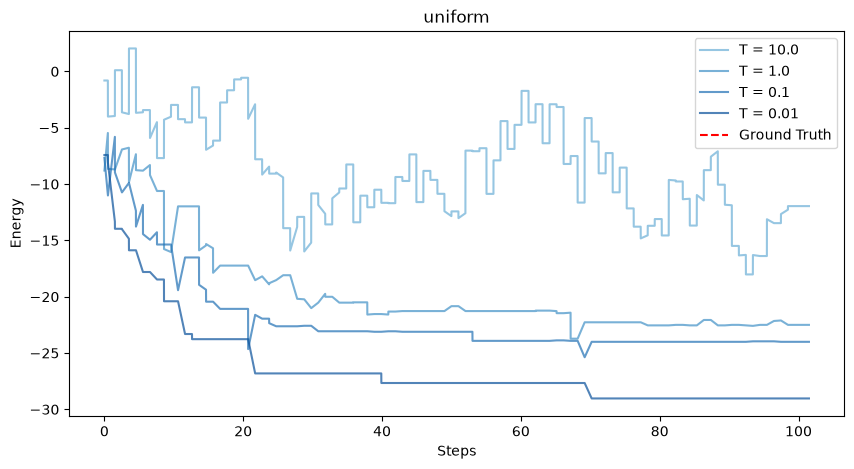

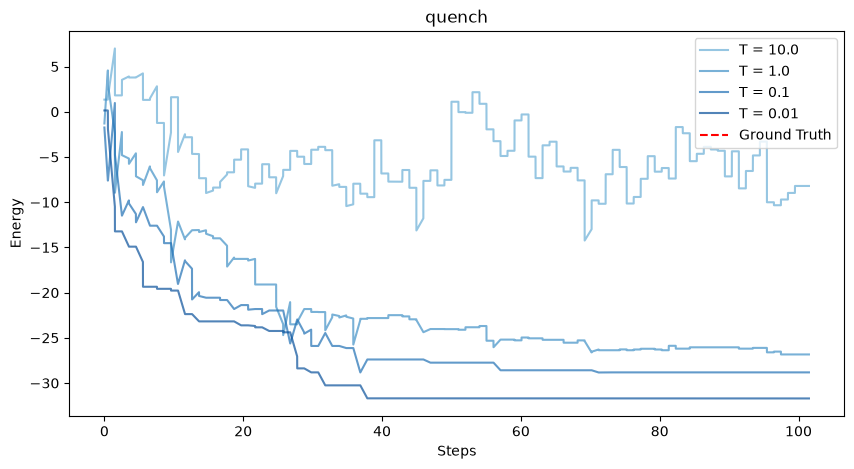

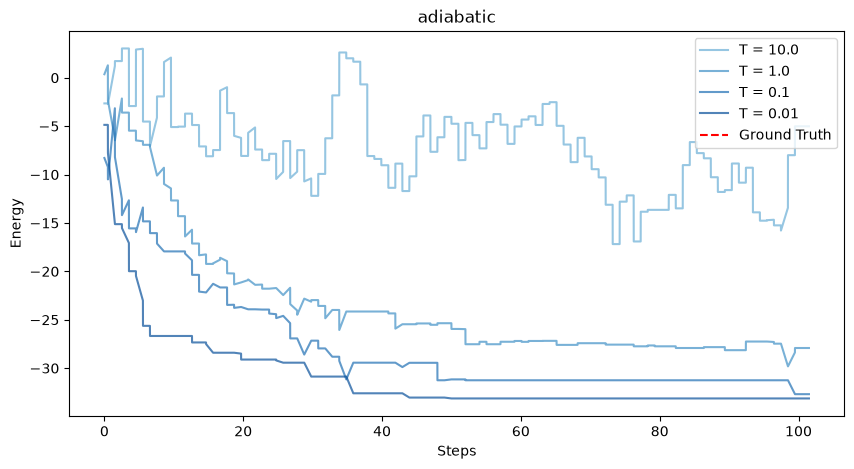

In [73]:



#model.get_lowest_energy()
model_lowest = np.nan#model.lowest_energy
optimal_energies_found = []




uni_chains = np.array(uni_chains)
c_chains = np.array(c_chains)
q_chains = np.array(q_chains)
adi_chains = np.array(adi_chains)







def plot_PT(all_energies_found, title, color_func):
    timesteps_ = np.linspace(0, n_steps+1, 2*(n_steps//2)+1)
    timesteps_ = np.repeat(timesteps_, 2)  # Repeat each timestep twice to match energy history recording points   

    timesteps_[::2] = timesteps_[::2]-0.5  # Shift timesteps to align with energy history recording points
    timesteps_[1::2] = timesteps_[1::2]+0.5  # Shift timesteps to align with energy history recording points
    timesteps_[0] = 0
    timesteps  = timesteps_
    plt.figure(figsize=(10, 5))
    for i in range(all_energies_found[0].shape[0]):
        label = "T = "+str(temps[i])
        color = color_func(0.5 + 0.5*i/all_energies_found[0].shape[0])  # Vary color for each run
        plt.plot(timesteps,np.mean(all_energies_found[:,i,:], axis = 0), label=label, color=color, alpha=0.7)


    # plot exact minima
    plt.axhline(y=model_lowest, color='red', linestyle='--', label='Ground Truth')  

    plt.xlabel('Steps')
    plt.ylabel('Energy')
    plt.title(title)
    plt.legend()
    plt.show()

plot_PT(c_chains, "local", plt.cm.Blues)
plot_PT(uni_chains, "uniform", plt.cm.Blues)
plot_PT(q_chains, "quench", plt.cm.Blues)
plot_PT(adi_chains, "adiabatic", plt.cm.Blues)






In [74]:
def plot_lowest_PT(all_energies_founds, colors, labels):

    timesteps_ = np.linspace(0, n_steps+1, 2*(n_steps//2)+1)
    timesteps_ = np.repeat(timesteps_, 2)  # Repeat each timestep twice to match energy history recording points   

    timesteps_[::2] = timesteps_[::2]-0.5  # Shift timesteps to align with energy history recording points
    timesteps_[1::2] = timesteps_[1::2]+0.5  # Shift timesteps to align with energy history recording points
    timesteps_[0] = 0
    timesteps  = timesteps_
    plt.figure(figsize=(10, 5))
    for i, all_energies_found in enumerate(all_energies_founds):
        plt.plot(timesteps,np.mean(all_energies_found[:,-1,:], axis = 0), label=labels[i], color=colors[i], alpha=0.7)


    # plot exact minima
    plt.axhline(y=model_lowest, color='red', linestyle='--', label='Ground Truth')  

    plt.xlabel('Steps')
    plt.ylabel('Energy')
    plt.title("QePT")
    plt.legend()
    plt.show()
    

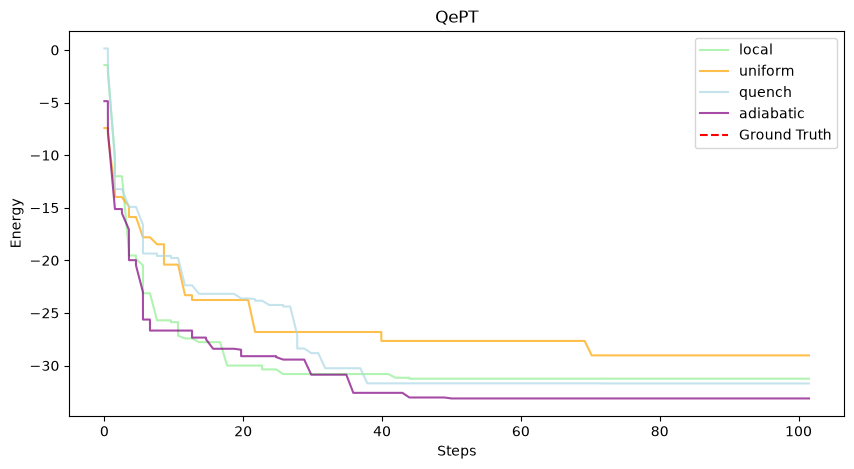

In [75]:
plot_lowest_PT([c_chains,uni_chains,q_chains,adi_chains],["lightgreen", "orange", "lightblue", "purple"],["local","uniform", "quench", "adiabatic"])
